In [11]:
import os
import json
from tqdm import tqdm
from PIL import Image
from pathlib import Path
import torch
import pandas as pd
import torch.nn as nn
import torch.optim as optim
import numpy as np
from torch.utils.data import DataLoader, Dataset
from torchvision.models import resnet101
from torchvision import transforms
from transformers import BertTokenizer
from transformers import get_cosine_schedule_with_warmup
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# device = torch.device('cpu')

class TextEncoder(nn.Module):
    def __init__(self, vocab_size, max_len, embed_dim=768, num_layers=6, nhead=8):
        super(TextEncoder, self).__init__()
        
        self.embed_dim = embed_dim
        self.max_len = max_len
        
        # Word embeddings
        self.token_embeddings = nn.Embedding(vocab_size, embed_dim)
        
        # Learnable [CLS] token
        self.cls_token = nn.Parameter(torch.randn(1, 1, embed_dim))
        
        # Learnable positional embeddings
        
        self.position_embeddings = nn.Parameter(torch.randn(1, max_len + 1, embed_dim))  # +1 for CLS
        
        # Transformer encoder layers
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=nhead, batch_first=True)
        self.transformer_encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
    
    def forward(self, input_ids, attention_mask= None):
        """
        input_ids: Tensor of shape (batch_size, seq_len)
        """
        batch_size, seq_len = input_ids.size()
        
        # Embed tokens
        token_embeds = self.token_embeddings(input_ids)  # (batch_size, seq_len, embed_dim)
        
        # Expand [CLS] token to batch size and concatenate at beginning
        cls_tokens = self.cls_token.expand(batch_size, -1, -1)  # (batch_size, 1, embed_dim)
        embeddings = torch.cat([cls_tokens, token_embeds], dim=1)  # (batch_size, seq_len + 1, embed_dim)
        
        # Add positional embeddings
        self.dropout = nn.Dropout(0.1)
        embeddings = self.dropout(embeddings + self.position_embeddings[:, :seq_len + 1, :])

        # Pass through Transformer Encoder and Use the attention mask for padding tokens
        if attention_mask is not None:
            # Transformer requires the mask to have shape (batch_size, seq_len + 1)
            attention_mask = torch.cat([torch.ones(batch_size, 1).to(input_ids.device), attention_mask], dim=1)
            src_key_padding_mask = attention_mask == 0
        else:
            src_key_padding_mask = None
        
        encoded_output = self.transformer_encoder(embeddings, src_key_padding_mask= src_key_padding_mask)  # Masking padding tokens)  # (batch_size, seq_len + 1, embed_dim)
        
        
        # Return the [CLS] token's output representation
        cls_output = encoded_output[:, 0, :]  # (batch_size, embed_dim)
        
        return cls_output

class ImageEncoder(nn.Module):
    def __init__(self, dvembed=768):
        super(ImageEncoder, self).__init__()
        
        # Load pretrained ResNet101
        resnet = resnet101(pretrained=True)
        modules = list(resnet.children())[:-2]  # remove GAP and FC
        self.resnet = nn.Sequential(*modules)
        
        # Freeze ResNet parameters
        for param in self.resnet.parameters():
            param.requires_grad = False
        
        # Linear projection from 2048 -> dvembed
        self.proj = nn.Linear(2048, dvembed)
        
    def forward(self, images):
        features = self.resnet(images)  # [B, 2048, h, w]
        B, C, h, w = features.size()
        
        # reshape to (B, h*w, 2048)
        features = features.permute(0, 2, 3, 1).reshape(B, h*w, C)
        
        # linear projection (project 2048-dim to dvembed)
        features = self.proj(features)  # [B, h*w, dvembed]
        
        return features

class CrossAttentionFusion(nn.Module):
    def __init__(self, embed_dim=768, num_heads=8):
        super(CrossAttentionFusion, self).__init__()
        
        # Cross-attention layer (MultiheadAttention)
        self.cross_attention = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=num_heads, batch_first=True)
    
    def forward(self, text_features, image_features):
        """
        text_features: Tensor of shape (batch_size, 1, embed_dim) -> [CLS] token feature
        image_features: Tensor of shape (batch_size, num_regions, embed_dim) -> Image features
        """
        
        # Cross-attention: text features as query, image features as key and value
        attn_output, attn_weights = self.cross_attention(text_features, image_features, image_features)
        
        # We only care about the output of the [CLS] token (0th index)
        # The output shape will be (batch_size, 1, embed_dim)
        fused_features = attn_output[:,0:1,:]  # Shape becomes (batch_size, 1, embed_dim)
        self.dropout = nn.Dropout(0.1)
        fused_features = self.dropout(fused_features.squeeze(1))
        
        return fused_features
    
class Classifier(nn.Module):
    def __init__(self, d_embed=768, hidden_dim=500, num_classes=28):
        super(Classifier, self).__init__()
        
        self.mlp = nn.Sequential(
            nn.Linear(d_embed, hidden_dim),  # 768 -> 500
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(hidden_dim, num_classes)  # 500 -> num_classes
        )
        
    def forward(self, x):
        """
        x: input tensor of shape (batch_size, d_embed)
        """
        return self.mlp(x)

class VQAModel(nn.Module):
    def __init__(self, vocab_size, max_len, num_classes):
        super(VQAModel, self).__init__()
        
        self.text_encoder = TextEncoder(vocab_size, max_len)
        self.image_encoder = ImageEncoder()
        self.cross_attention = CrossAttentionFusion()
        self.classifier = Classifier(num_classes=num_classes)
        
    def forward(self, input_ids, images, attention_mask):
        text_features = self.text_encoder(input_ids, attention_mask)          # (B, 768)
        image_features = self.image_encoder(images)           # (B, 64, 768)
        
        text_features = text_features.unsqueeze(1)            # (B, 1, 768)
        fused_features = self.cross_attention(text_features, image_features)  # (B, 768)
        
        logits = self.classifier(fused_features)
        return logits

def train_model(model, train_loader, val_loader, optimizer, scheduler, start_epoch, num_epochs=10, best_val_acc = 0):
    model = model.to(device)
    # optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    criterion = nn.CrossEntropyLoss()
    
    best_val_loss = float('inf')
    # best_val_acc = 0.0
    # total_steps = num_epochs*len(train_loader)
    # warmup_steps = int(0.1*total_steps)
    # scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)
    acc_loss_df = []
    
    for epoch in range(start_epoch, num_epochs):
        model.train()
        running_loss = 0
        correct = 0
        total = 0
        
        for images, input_ids, attention_mask, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Training]", ncols=100):
            input_ids, images, labels, attention_mask = input_ids.to(device), images.to(device), labels.to(device), attention_mask.to(device)
            
            optimizer.zero_grad()
            outputs = model(input_ids, images, attention_mask)
            # print(outputs.shape)
            # print(labels.shape)
            loss = criterion(outputs, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            scheduler.step()
            
            running_loss += loss.item()*labels.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
        
        train_loss = running_loss / total
        train_acc = correct / total
        
        # Validation
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        
        acc_loss = {"Epoch" :epoch+1, "Train Loss": train_loss, "Train Acc" : train_acc, "Val Loss" : val_loss, "Val Acc" : val_acc}
        acc_loss_df.append(acc_loss)
        for param_group in optimizer.param_groups:
            current_lr = param_group['lr']

        print(f"Epoch {epoch+1} | LR: {current_lr:.8f} | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
        # Save checkpoint if validation improves
        save_checkpoint = False
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            save_checkpoint = True
        
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            save_checkpoint = True
        
        if save_checkpoint:
            # During training, after an epoch with improved validation accuracy
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),  # optional but recommended
                'best_val_acc': best_val_acc,
                'best_val_loss' : best_val_loss
            }, f"checkpoint_epoch{epoch+1}.pth")

            # torch.save(model.state_dict(), f"checkpoint_epoch{epoch+1}.pth")
            print(f"Checkpoint saved at epoch {epoch+1}")
            
    df = pd.DataFrame(acc_loss_df)
    df.to_csv(base_path/f'Loss_Accuracy_parameters.csv')
def evaluate(model, data_loader, criterion):
    model.eval()
    running_loss = 0
    correct = 0
    total = 0
    preds_t =[]
    labels_t = []
    
    with torch.no_grad():
        for images, input_ids, attention_mask, labels in tqdm(data_loader):
            input_ids, images, labels, attention_mask = input_ids.to(device), images.to(device), labels.to(device), attention_mask.to(device)
            outputs = model(input_ids, images, attention_mask)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item()*labels.size(0)
            _, preds = outputs.max(1)
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)

            # Convert tensors to numpy arrays if needed
            preds_np = preds.cpu().numpy() if isinstance(preds, torch.Tensor) else preds
            labels_np = labels.cpu().numpy() if isinstance(labels, torch.Tensor) else labels
            preds_t.append(preds_np)
            labels_t.append(labels_np)
            # return images, input_ids, attention_mask, labels, preds_np, labels_np            
    return running_loss / total, correct / total, preds_t, labels_t

class CLEVRVQADataset(Dataset):
    def __init__(self, image_dir, question_path, tokenizer, transform=None, max_len = 48):
        """
        Args:
            image_dir (str): Path to the directory with images.
            question_path (str): Path to the JSON file with questions.
            tokenizer (Tokenizer): A Huggingface tokenizer (like BertTokenizer).
            transform (callable, optional): Optional transform to be applied on an image.
            max_len (int): Maximum token length for questions.
        """
        self.image_dir = image_dir
        self.transform = transform
        self.tokenizer = tokenizer
        self.max_len = max_len
        # Load questions
        with open(question_path, 'r') as f:
            questions_json = json.load(f)
        
        self.questions = questions_json['questions']  # List of question dictionaries
        
        # Create a mapping of answer strings to integer labels (for classification)
        all_answers = list({q['answer'] for q in self.questions})
        self.answer_to_idx = {ans: idx for idx, ans in enumerate(sorted(all_answers))}
        self.idx_to_answer = {idx: ans for ans, idx in self.answer_to_idx.items()}

    def __len__(self):
        return len(self.questions)

    def __getitem__(self, idx):
        q = self.questions[idx]

        # Load image
        image_filename = q['image_filename']  # like 'CLEVR_train_000000.png'
        image_path = os.path.join(self.image_dir, image_filename)
        image = Image.open(image_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
        
        # Tokenize question
        question = q['question']
        encoding = self.tokenizer(question, padding='max_length', max_length=self.max_len, truncation= True, return_tensors='pt')
        
        input_ids = encoding['input_ids'].squeeze(0)         # shape: (max_len,)
        attention_mask = encoding['attention_mask'].squeeze(0) # shape: (max_len,)

        # Map answer to index
        answer = q['answer']
        answer_idx = self.answer_to_idx[answer]

        return (image, input_ids, attention_mask, torch.tensor(answer_idx))                 # (3, H, W)


# Paths
base_path = Path().resolve()
img_dir = base_path/'CLEVR_COL774_A4'/'images'
train_img_dir = img_dir/'trainA'
val_img_dir = img_dir/'valA'
test_img_dir = img_dir/'testA'
testB_img_dir = img_dir/'testB'
q_json = base_path/'CLEVR_COL774_A4'/'questions'
train_q_json = q_json/'CLEVR_trainA_questions.json'
val_q_json = q_json/'CLEVR_valA_questions.json'
test_q_json = q_json/'CLEVR_testA_questions.json'
testB_q_json = q_json/'CLEVR_testB_questions.json'

# Tokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

# Image transformations
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])
# Parameters
num_classes = 28
batch_size = 64
vocab_size = tokenizer.vocab_size

# with open(train_q_json, 'r') as f:
#     train_dict = json.load(f)
max_len = 48
# for item in train_dict['questions']:
#     max_len = max(max_len, len(tokenizer.tokenize(item['question'])))

# Dataset
train_dataset = CLEVRVQADataset(image_dir=train_img_dir, question_path=train_q_json, tokenizer=tokenizer, transform=image_transform, max_len= max_len)
val_dataset = CLEVRVQADataset(image_dir=val_img_dir, question_path=val_q_json, tokenizer=tokenizer, transform=image_transform, max_len= max_len )
test_dataset = CLEVRVQADataset(image_dir=test_img_dir, question_path=test_q_json, tokenizer=tokenizer, transform=image_transform, max_len= max_len)
testB_dataset = CLEVRVQADataset(image_dir=testB_img_dir, question_path=testB_q_json, tokenizer=tokenizer, transform=image_transform, max_len= max_len)
# DataLoader
train_loader = DataLoader(train_dataset, batch_size = batch_size, shuffle=True, num_workers=32)
val_loader = DataLoader(val_dataset, batch_size = batch_size, shuffle=False, num_workers=32)
test_loader = DataLoader(test_dataset, batch_size = batch_size, shuffle=False, num_workers=32)
testB_loader = DataLoader(testB_dataset, batch_size = batch_size, shuffle=False, num_workers=32)

model = VQAModel(vocab_size=vocab_size, max_len=max_len, num_classes=num_classes)
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.01)
best_val_loss = float('inf')
best_val_acc = 0.0
num_epochs = 30
start_epoch = 0
checkpoint_path = 'checkpoint_epoch25.pth'
total_steps = num_epochs*len(train_loader)
warmup_steps = int(0.1*total_steps)
scheduler = get_cosine_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)
checkpoint = torch.load(checkpoint_path)
model.load_state_dict(checkpoint['model_state_dict'])
optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
for state in optimizer.state.values():
    for k, v in state.items():
        if isinstance(v, torch.Tensor):
            state[k] = v.to(device)

start_epoch = checkpoint['epoch'] + 1
best_val_acc = checkpoint['best_val_acc']
criterion = nn.CrossEntropyLoss()
model = model.to(device)
print('Evaluation starts')
running_loss, acc, pred_t, label_t = evaluate(model, testB_loader, criterion)
preds_np = np.concatenate(pred_t)
labels_np = np.concatenate(label_t)

 # Calculate metrics
accuracy = accuracy_score(labels_np, preds_np)
precision = precision_score(labels_np, preds_np, average='macro')   # or 'micro', 'weighted'
recall = recall_score(labels_np, preds_np, average='macro')
f1 = f1_score(labels_np, preds_np, average='macro')

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1 Score: {f1:.4f}")
print(f"Resuming training from epoch {start_epoch}")
# train_model(model= model, train_loader = train_loader, val_loader = val_loader, optimizer = optimizer, scheduler = scheduler, start_epoch = start_epoch, num_epochs=num_epochs, best_val_acc = best_val_acc)

/home/m3rg2000/miniconda3/envs/torch-env/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/m3rg2000/miniconda3/envs/torch-env/lib/python3.9/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet101_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet101_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/tmp/ipykernel_389384/199426131.py:372: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytor

Evaluation starts


100%|██████████| 1172/1172 [07:50<00:00,  2.49it/s]

Test Accuracy: 0.6953
Test Precision: 0.5087
Test Recall: 0.4984
Test F1 Score: 0.5014
Resuming training from epoch 25



/home/m3rg2000/miniconda3/envs/torch-env/lib/python3.9/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [12]:
with open(testB_q_json, 'r') as f:
    questions_json = json.load(f)
        
questions = questions_json['questions']  # List of question dictionaries

# Create a mapping of answer strings to integer labels (for classification)
all_answers = list({q['answer'] for q in questions})
answer_to_idx = {ans: idx for idx, ans in enumerate(sorted(all_answers))}
idx_to_answer = {idx: ans for ans, idx in answer_to_idx.items()}

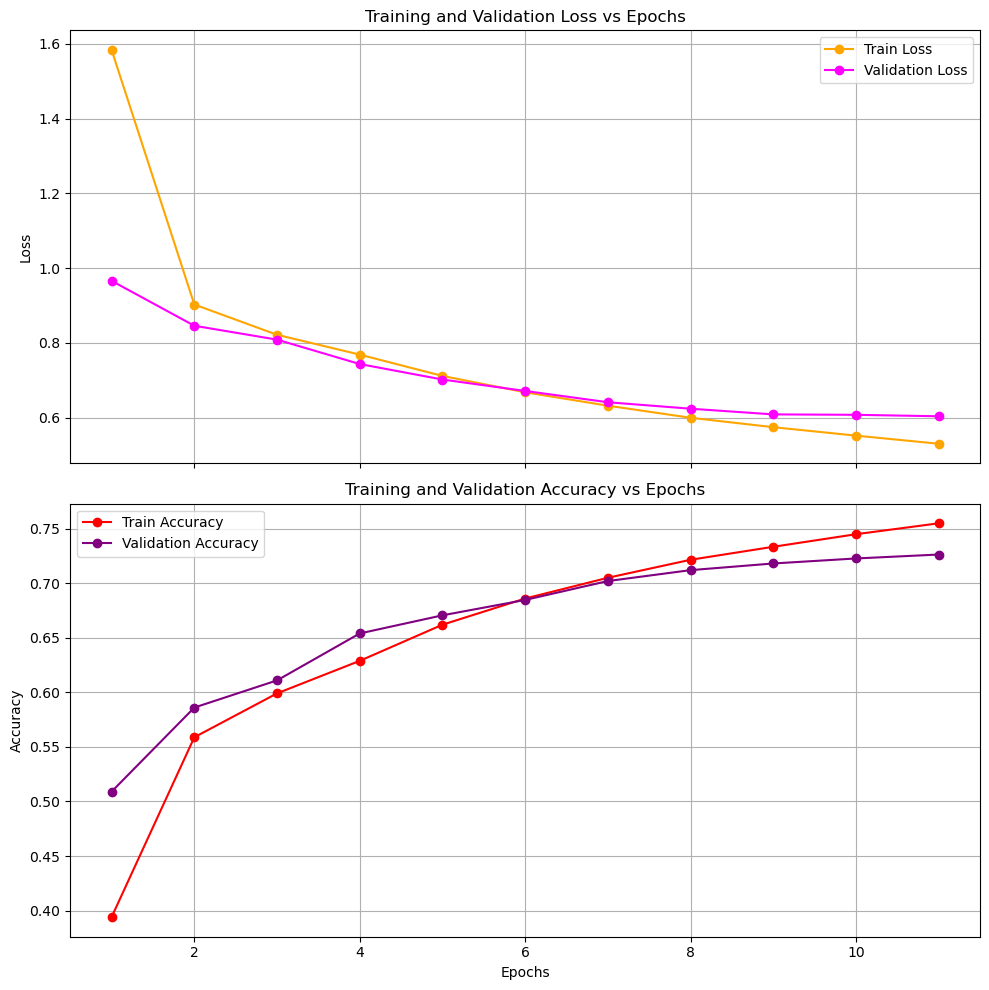

In [ ]:
# Plot for Part 8 

import matplotlib.pyplot as plt

# Data
epochs = list(range(1, 12))
train_loss = [1.5836, 0.9028, 0.8219, 0.7688, 0.7118, 0.6680, 0.6322, 0.5999, 0.5747, 0.5521, 0.5304]
train_acc = [0.3941, 0.5588, 0.5990, 0.6288, 0.6619, 0.6859, 0.7049, 0.7214, 0.7333, 0.7448, 0.7548]
val_loss = [0.9661, 0.8460, 0.8089, 0.7436, 0.7022, 0.6716, 0.6414, 0.6241, 0.6089, 0.6078, 0.6039]
val_acc = [0.5090, 0.5860, 0.6109, 0.6539, 0.6705, 0.6846, 0.7019, 0.7119, 0.7180, 0.7226, 0.7262]

# Create subplots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

# Plot Loss
ax1.plot(epochs, train_loss, label='Train Loss', marker='o', color='orange')
ax1.plot(epochs, val_loss, label='Validation Loss', marker='o', color='magenta')
ax1.set_title('Training and Validation Loss vs Epochs')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

# Plot Accuracy
ax2.plot(epochs, train_acc, label='Train Accuracy', marker='o', color='red')
ax2.plot(epochs, val_acc, label='Validation Accuracy', marker='o', color='purple')
ax2.set_title('Training and Validation Accuracy vs Epochs')
ax2.set_xlabel('Epochs')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

# Display plot
plt.tight_layout()
plt.show()


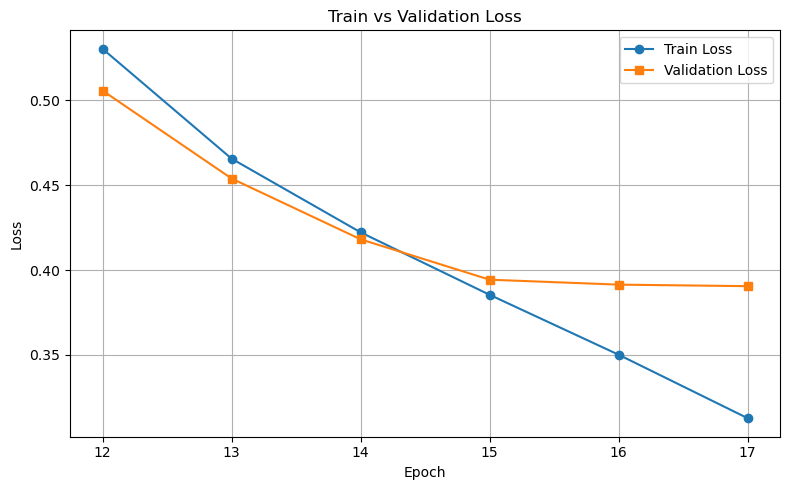

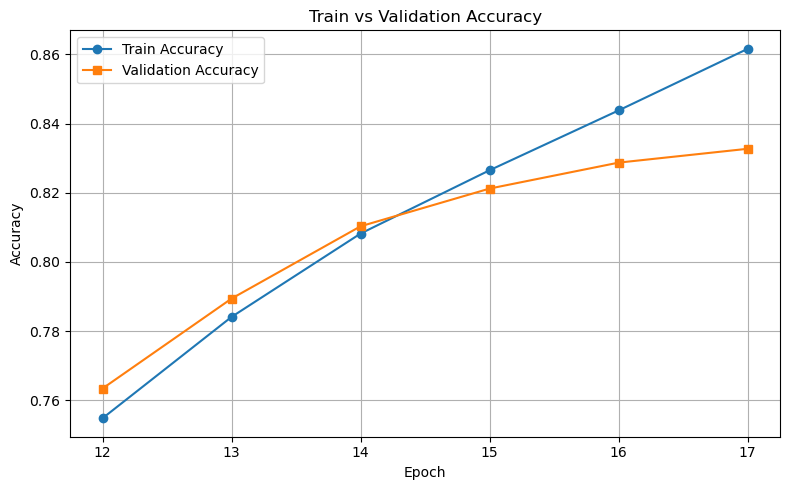

In [ ]:
#  Plot for Part 9

import matplotlib.pyplot as plt

# Data
epochs = [12, 13, 14, 15, 16, 17]
train_loss = [0.5303, 0.4656, 0.4222, 0.3854, 0.3501, 0.3127]
val_loss =   [0.5057, 0.4539, 0.4181, 0.3943, 0.3914, 0.3905]
train_acc =  [0.7548, 0.7841, 0.8082, 0.8265, 0.8438, 0.8616]
val_acc =    [0.7634, 0.7894, 0.8103, 0.8212, 0.8287, 0.8327]

# Plot Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, marker='o', label='Train Loss')
plt.plot(epochs, val_loss, marker='s', label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train and Validation Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, marker='o', label='Train Accuracy')
plt.plot(epochs, val_acc, marker='s', label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Train and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


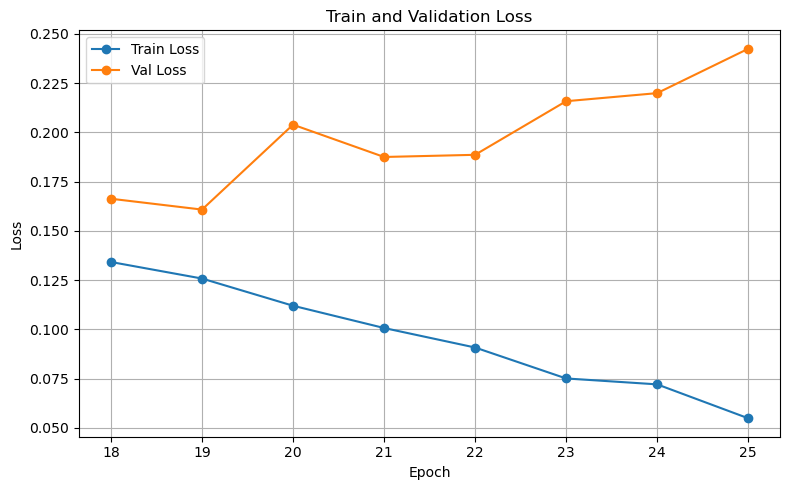

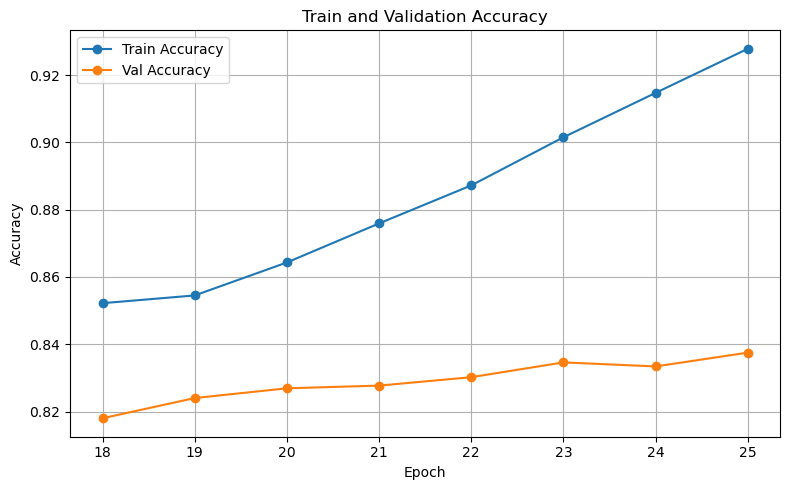

In [9]:
# Plot for Part 10a 

import matplotlib.pyplot as plt

# Epochs and corresponding values
epochs = list(range(18, 26))  # Epochs 18 to 25 (excluding 26)

train_loss = [0.1342, 0.1258, 0.1120, 0.1007, 0.0908, 0.0751, 0.0721, 0.0549]
val_loss =   [0.1663, 0.1608, 0.2039, 0.1875, 0.1886, 0.2158, 0.2199, 0.2424]

train_acc = [0.8522, 0.8545, 0.8643, 0.8759, 0.8872, 0.9015, 0.9147, 0.9278]
val_acc =   [0.8180, 0.8240, 0.8269, 0.8277, 0.8302, 0.8346, 0.8334, 0.8375]

# Plot Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label='Train Loss', marker='o')
plt.plot(epochs, val_loss, label='Val Loss', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train and Validation Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_acc, label='Train Accuracy', marker='o')
plt.plot(epochs, val_acc, label='Val Accuracy', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Train and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
